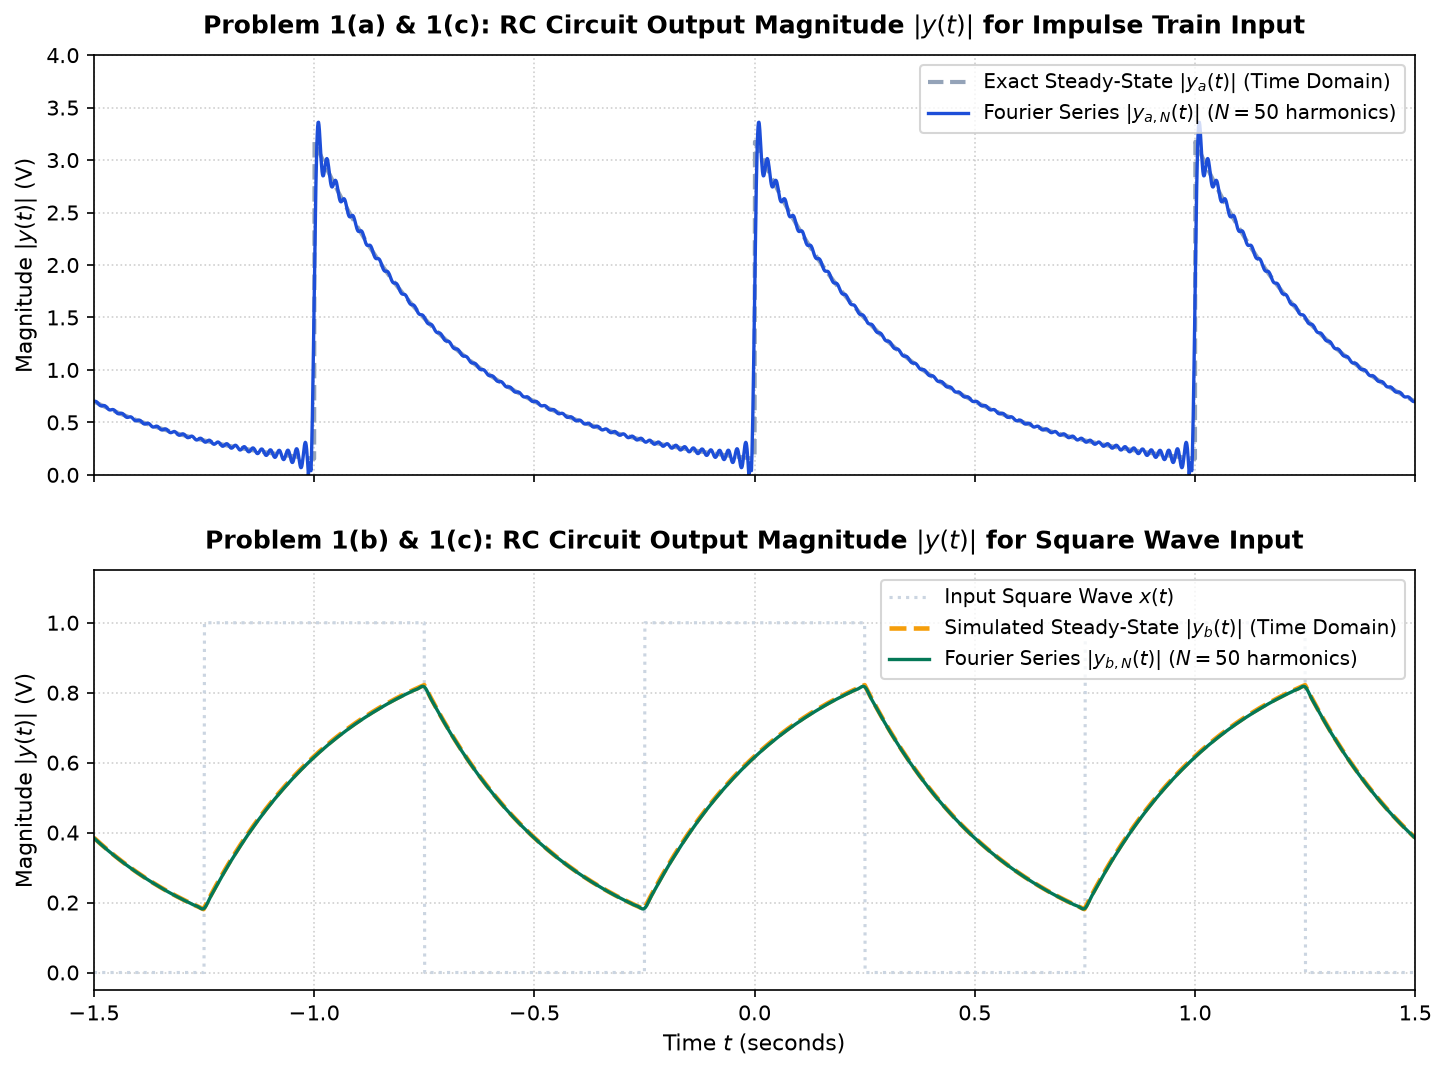

PROBLEM 2(a): SAWTOOTH SIGNAL x(t) = t, 0 <= t < 1 (T0 = 1, w0 = 2*pi)
  k = 0: Analytical c_0 = +0.500000 +0.000000j | Numerical c_0 = +0.500000 +0.000000j
  k = 1: Analytical c_1 = +0.000000 +0.159155j | Numerical c_1 = +0.000000 +0.159155j
  k = 2: Analytical c_2 = +0.000000 +0.079577j | Numerical c_2 = -0.000000 +0.079577j
  k = 3: Analytical c_3 = +0.000000 +0.053052j | Numerical c_3 = -0.000000 +0.053052j
  k = 4: Analytical c_4 = +0.000000 +0.039789j | Numerical c_4 = -0.000000 +0.039789j

Error Energy E_N over one period [0, 1] for Sawtooth Signal:
  N = 1: E_1 (Parseval) = 0.032673 | E_1 (Direct Integral) = 0.032673
  N = 2: E_2 (Parseval) = 0.020008 | E_2 (Direct Integral) = 0.020008
  N = 3: E_3 (Parseval) = 0.014379 | E_3 (Direct Integral) = 0.014379
  N = 4: E_4 (Parseval) = 0.011212 | E_4 (Direct Integral) = 0.011212

PROBLEM 2(b): RECTANGULAR SIGNAL y(t) (T0 = 2, w0 = pi)
  k = 0: Analytical c_0 = +0.500000 +0.000000j | Numerical c_0 = +0.500000 +0.000000j
  k = 1: Analy

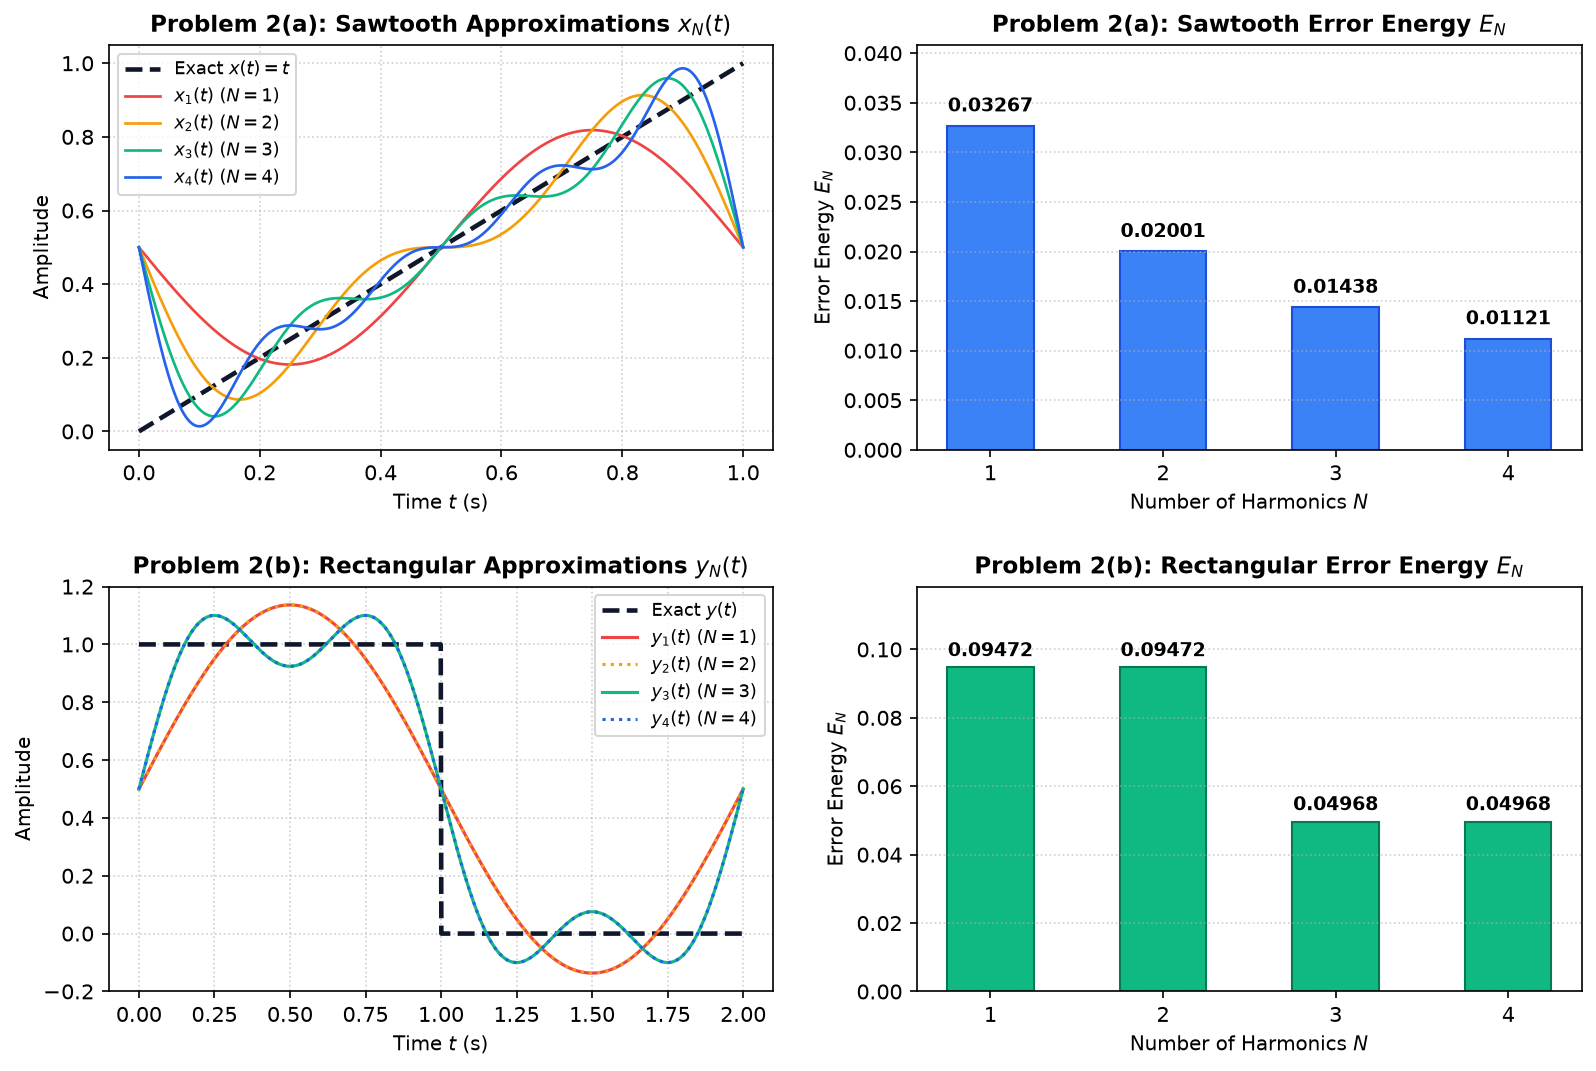

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
%matplotlib inline

R = 330.0          
C = 1000e-6        
RC = R * C          


T_p1 = 1.0
w0_p1 = 2.0 * np.pi / T_p1

# Choose a finite number of harmonics N and a sampling interval dt
dt = 0.001                                 
t_p1 = np.arange(-1.5, 1.5, dt)             
N_harmonics = 50                            


def H_rc(w, rc=RC):
    """
    Frequency response H(jw) of the RC low-pass circuit.
    Given impulse response: h(t) = (1 / RC) * exp(-t / RC) * u(t)
    Fourier Transform:      H(jw) = 1 / (1 + j * w * RC)
    """
    return 1.0 / (1.0 + 1j * w * rc)


def synthesize_fourier_series(t, w0, coeff_func, N):
    """
    Evaluate the truncated complex exponential Fourier series:
        f_N(t) = sum_{k=-N}^{N} c_k * exp(j * k * w0 * t)
    """
    result = np.zeros_like(t, dtype=complex)
    for k in range(-N, N + 1):
        ck = coeff_func(k)
        result += ck * np.exp(1j * k * w0 * t)
    return result


def ak_impulse_train(k):
    """Complex Fourier series coefficients a_k of the unit impulse train (T = 1)."""
    return 1.0 + 0.0j


def bk_impulse_train(k):
    """Output Fourier series coefficients b_k = a_k * H(j * k * w0)."""
    return ak_impulse_train(k) * H_rc(k * w0_p1)


# Discrete-time representation of the impulse train on the simulation grid
x_a_time = np.zeros_like(t_p1)
impulse_indices = np.where(np.isclose(np.mod(t_p1 + 0.5, 1.0) - 0.5, 0.0, atol=dt / 2))[0]
x_a_time[impulse_indices] = 1.0 / dt

t_mod_1 = np.mod(t_p1, T_p1)
y_a_exact = (1.0 / RC) * np.exp(-t_mod_1 / RC) / (1.0 - np.exp(-T_p1 / RC))

# Truncated Fourier series reconstruction of the output y_a(t) using N = 50 harmonics
y_a_fs = synthesize_fourier_series(t_p1, w0_p1, bk_impulse_train, N_harmonics)


x_b_time = np.where(np.abs(np.mod(t_p1 + 0.5, 1.0) - 0.5) <= 0.25, 1.0, 0.0)


def ak_square_wave(k):
    """
    Complex Fourier series coefficients a_k of the symmetric square wave (T = 1):
        a_0 = 1/2
        a_k = sin(pi * k / 2) / (pi * k)  for k != 0
    """
    if k == 0:
        return 0.5 + 0.0j
    return np.sin(np.pi * k / 2.0) / (np.pi * k) + 0.0j


def bk_square_wave(k):
    """Output Fourier series coefficients b_k = a_k * H(j * k * w0)."""
    return ak_square_wave(k) * H_rc(k * w0_p1)


# Time-domain steady-state output via circular convolution over one period
t_one_period = np.arange(0, T_p1, dt)
h_periodic = (1.0 / RC) * np.exp(-t_one_period / RC) / (1.0 - np.exp(-T_p1 / RC))
x_b_one_period = np.where((t_one_period <= 0.25) | (t_one_period >= 0.75), 1.0, 0.0)
y_b_one_period = np.real(np.fft.ifft(np.fft.fft(x_b_one_period) * np.fft.fft(h_periodic))) * dt
y_b_time = np.roll(np.tile(y_b_one_period, 3), -int(round(0.5 / dt)))

# Truncated Fourier series reconstruction of the output y_b(t) using N = 50 harmonics
y_b_fs = synthesize_fourier_series(t_p1, w0_p1, bk_square_wave, N_harmonics)


fig1, axes1 = plt.subplots(2, 1, figsize=(10, 7.5), dpi=150, sharex=True)

# Subplot 1: Impulse Train Output Magnitude |y_a(t)|
ax = axes1[0]
ax.plot(t_p1, np.abs(y_a_exact), color="#94a3b8", linestyle="--", linewidth=2.0,
        label="Exact Steady-State $|y_a(t)|$ (Time Domain)")
ax.plot(t_p1, np.abs(y_a_fs), color="#1d4ed8", linewidth=1.6,
        label=f"Fourier Series $|y_{{a,N}}(t)|$ ($N = {N_harmonics}$ harmonics)")
ax.set_title("Problem 1(a) & 1(c): RC Circuit Output Magnitude $|y(t)|$ for Impulse Train Input",
             fontsize=12, fontweight="bold", pad=10)
ax.set_ylabel("Magnitude $|y(t)|$ (V)", fontsize=10.5)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=9.5)
ax.set_ylim(0, 4.0)

# Subplot 2: Square Wave Output Magnitude |y_b(t)|
ax = axes1[1]
ax.plot(t_p1, x_b_time, color="#cbd5e1", linestyle=":", linewidth=1.5,
     label="Input Square Wave $x(t)$")
ax.plot(t_p1, np.abs(y_b_time), color="#f59e0b", linestyle="--", linewidth=2.2,
        label="Simulated Steady-State $|y_b(t)|$ (Time Domain)")
ax.plot(t_p1, np.abs(y_b_fs), color="#047857", linewidth=1.6,
     label=f"Fourier Series $|y_{{b,N}}(t)|$ ($N = {N_harmonics}$ harmonics)")
ax.set_title("Problem 1(b) & 1(c): RC Circuit Output Magnitude $|y(t)|$ for Square Wave Input",
             fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Time $t$ (seconds)", fontsize=10.5)
ax.set_ylabel("Magnitude $|y(t)|$ (V)", fontsize=10.5)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=9.5)
ax.set_ylim(-0.05, 1.15)
ax.set_xlim(-1.5, 1.5)

fig1.tight_layout(pad=2.0)
fig1.savefig("problem1c_rc_output_magnitude.png", bbox_inches="tight")
plt.show()


T0_2a = 1.0
w0_2a = 2.0 * np.pi / T0_2a


def ck_sawtooth(k):
    """
    Analytical complex Fourier series coefficients c_k for sawtooth x(t) = t on [0, 1):
        c_0 = 1/2
        c_k = j / (2 * pi * k)  for k != 0
    """
    if k == 0:
        return 0.5 + 0.0j
    return 1j / (2.0 * np.pi * k)


def ck_sawtooth_numerical(k):
    """Compute c_k numerically via quadrature integration over [0, T0]."""
    real_part, _ = quad(lambda t: t * np.cos(-k * w0_2a * t) / T0_2a, 0.0, T0_2a)
    imag_part, _ = quad(lambda t: t * np.sin(-k * w0_2a * t) / T0_2a, 0.0, T0_2a)
    return real_part + 1j * imag_part


print("=" * 72)
print("PROBLEM 2(a): SAWTOOTH SIGNAL x(t) = t, 0 <= t < 1 (T0 = 1, w0 = 2*pi)")
print("=" * 72)
for k in range(0, 5):
    ck_val = ck_sawtooth(k)
    ck_num = ck_sawtooth_numerical(k)
    print(f"  k = {k}: Analytical c_{k} = {ck_val.real:+.6f} {ck_val.imag:+.6f}j | "
          f"Numerical c_{k} = {ck_num.real:+.6f} {ck_num.imag:+.6f}j")

print("\nError Energy E_N over one period [0, 1] for Sawtooth Signal:")
E_total_2a = 1.0 / 3.0  # int_0^1 t^2 dt = 1/3
results_2a = []
for N in [1, 2, 3, 4]:
    # Method 1: Exact Time-Domain Quadrature Integral of |x(t) - x_N(t)|^2
    def integrand_2a(t):
        x_N_t = sum(ck_sawtooth(k) * np.exp(1j * k * w0_2a * t) for k in range(-N, N + 1))
        return np.abs(t - x_N_t) ** 2

    E_N_integral, _ = quad(integrand_2a, 0.0, T0_2a, limit=200)

    # Method 2: Parseval's Theorem: E_N = E_total - T0 * sum_{k=-N}^N |c_k|^2
    sum_ck_sq = sum(np.abs(ck_sawtooth(k)) ** 2 for k in range(-N, N + 1))
    E_N_parseval = E_total_2a - T0_2a * sum_ck_sq
    results_2a.append((N, E_N_parseval, E_N_integral))
    print(f"  N = {N}: E_{N} (Parseval) = {E_N_parseval:.6f} | "
          f"E_{N} (Direct Integral) = {E_N_integral:.6f}")


T0_2b = 2.0
w0_2b = 2.0 * np.pi / T0_2b


def ck_rect(k):
    """
    Analytical complex Fourier series coefficients c_k for rectangular wave y(t) (T0 = 2):
        c_0 = 1/2
        c_k = (1 - (-1)^k) / (j * 2 * pi * k) = -j / (pi * k) for odd k, 0 for even k != 0
    """
    if k == 0:
        return 0.5 + 0.0j
    if k % 2 == 0:
        return 0.0 + 0.0j
    return -1j / (np.pi * k)


def ck_rect_numerical(k):
    """Compute c_k numerically via quadrature integration over [0, T0] (nonzero on [0, 1])."""
    real_part, _ = quad(lambda t: 1.0 * np.cos(-k * w0_2b * t) / T0_2b, 0.0, 1.0)
    imag_part, _ = quad(lambda t: 1.0 * np.sin(-k * w0_2b * t) / T0_2b, 0.0, 1.0)
    return real_part + 1j * imag_part


print("\n" + "=" * 72)
print("PROBLEM 2(b): RECTANGULAR SIGNAL y(t) (T0 = 2, w0 = pi)")
print("=" * 72)
for k in range(0, 5):
    ck_val = ck_rect(k)
    ck_num = ck_rect_numerical(k)
    print(f"  k = {k}: Analytical c_{k} = {ck_val.real:+.6f} {ck_val.imag:+.6f}j | "
          f"Numerical c_{k} = {ck_num.real:+.6f} {ck_num.imag:+.6f}j")

print("\nError Energy E_N over one period [0, 2] for Rectangular Signal:")
E_total_2b = 1.0  # int_0^2 |y(t)|^2 dt = int_0^1 1^2 dt = 1
results_2b = []
for N in [1, 2, 3, 4]:
    # Method 1: Direct Time-Domain Quadrature Integral on [0, 1) and [1, 2)
    def integrand_2b_high(t):
        y_N_t = sum(ck_rect(k) * np.exp(1j * k * w0_2b * t) for k in range(-N, N + 1))
        return np.abs(1.0 - y_N_t) ** 2

    def integrand_2b_low(t):
        y_N_t = sum(ck_rect(k) * np.exp(1j * k * w0_2b * t) for k in range(-N, N + 1))
        return np.abs(0.0 - y_N_t) ** 2

    e1, _ = quad(integrand_2b_high, 0.0, 1.0, limit=200)
    e2, _ = quad(integrand_2b_low, 1.0, 2.0, limit=200)
    E_N_integral = e1 + e2

    # Method 2: Parseval's Theorem: E_N = E_total - T0 * sum_{k=-N}^N |c_k|^2
    sum_ck_sq = sum(np.abs(ck_rect(k)) ** 2 for k in range(-N, N + 1))
    E_N_parseval = E_total_2b - T0_2b * sum_ck_sq
    results_2b.append((N, E_N_parseval, E_N_integral))
    print(f"  N = {N}: E_{N} (Parseval) = {E_N_parseval:.6f} | "
          f"E_{N} (Direct Integral) = {E_N_integral:.6f}")


t_2a_plot = np.linspace(0.0, T0_2a, 1000)
x_2a_plot = t_2a_plot
t_2b_plot = np.linspace(0.0, T0_2b, 1000)
y_2b_plot = np.where(t_2b_plot < 1.0, 1.0, 0.0)

fig2, axes2 = plt.subplots(2, 2, figsize=(11, 7.5), dpi=150)
colors_N = ["#ef4444", "#f59e0b", "#10b981", "#2563eb"]

# Top-left: Sawtooth Approximations x_N(t)
ax = axes2[0, 0]
ax.plot(t_2a_plot, x_2a_plot, color="#0f172a", linewidth=2.2, linestyle="--", label="Exact $x(t) = t$")
for idx, N in enumerate([1, 2, 3, 4]):
    fN = np.real(synthesize_fourier_series(t_2a_plot, w0_2a, ck_sawtooth, N))
    ax.plot(t_2a_plot, fN, color=colors_N[idx], linewidth=1.3, label=f"$x_{{{N}}}(t)$ ($N={N}$)")
ax.set_title("Problem 2(a): Sawtooth Approximations $x_N(t)$", fontsize=11, fontweight="bold")
ax.set_xlabel("Time $t$ (s)", fontsize=9.5)
ax.set_ylabel("Amplitude", fontsize=9.5)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=8.5)

# Top-right: Sawtooth Error Energy E_N
ax = axes2[0, 1]
N_vals = [r[0] for r in results_2a]
E_vals_2a = [r[1] for r in results_2a]
bars = ax.bar(N_vals, E_vals_2a, color="#3b82f6", width=0.5, edgecolor="#1d4ed8")
for bar, val in zip(bars, E_vals_2a):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.001, f"{val:.5f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_title("Problem 2(a): Sawtooth Error Energy $E_N$", fontsize=11, fontweight="bold")
ax.set_xlabel("Number of Harmonics $N$", fontsize=9.5)
ax.set_ylabel("Error Energy $E_N$", fontsize=9.5)
ax.set_xticks([1, 2, 3, 4])
ax.set_ylim(0, max(E_vals_2a) * 1.25)
ax.grid(True, axis="y", linestyle=":", alpha=0.6)

# Bottom-left: Rectangular Approximations y_N(t)
ax = axes2[1, 0]
ax.plot(t_2b_plot, y_2b_plot, color="#0f172a", linewidth=2.2, linestyle="--", label="Exact $y(t)$")
for idx, N in enumerate([1, 2, 3, 4]):
    fN = np.real(synthesize_fourier_series(t_2b_plot, w0_2b, ck_rect, N))
    ls = "-" if N in [1, 3] else ":"
    ax.plot(t_2b_plot, fN, color=colors_N[idx], linewidth=1.5, linestyle=ls, label=f"$y_{{{N}}}(t)$ ($N={N}$)")
ax.set_title("Problem 2(b): Rectangular Approximations $y_N(t)$", fontsize=11, fontweight="bold")
ax.set_xlabel("Time $t$ (s)", fontsize=9.5)
ax.set_ylabel("Amplitude", fontsize=9.5)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=8.5)

# Bottom-right: Rectangular Error Energy E_N
ax = axes2[1, 1]
E_vals_2b = [r[1] for r in results_2b]
bars = ax.bar(N_vals, E_vals_2b, color="#10b981", width=0.5, edgecolor="#047857")
for bar, val in zip(bars, E_vals_2b):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.002, f"{val:.5f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_title("Problem 2(b): Rectangular Error Energy $E_N$", fontsize=11, fontweight="bold")
ax.set_xlabel("Number of Harmonics $N$", fontsize=9.5)
ax.set_ylabel("Error Energy $E_N$", fontsize=9.5)
ax.set_xticks([1, 2, 3, 4])
ax.set_ylim(0, max(E_vals_2b) * 1.25)
ax.grid(True, axis="y", linestyle=":", alpha=0.6)

fig2.tight_layout(pad=2.0)
fig2.savefig("problem2_fourier_error_energy.png", bbox_inches="tight")
plt.show()